# 01 · Stage 0: Diagnose

**What this step does.** Runs your September Stage 0 script (`../stage0/stage0_diagnose.py`) on the **training split only**, then turns its output into a **frozen list of risk strata**.

**Why it matters.** Stage 0 has one narrow job: tell the audit **where to look**. It maps how the protected attributes, the other variables and the label connect. A subgroup with a causal pathway into the label is where label errors would most distort what a model learns. Without this step, the audit is scattershot, which was the problem with the earlier composite score.

**What Stage 0 does NOT claim.** It does not prove the true causal structure. Its "assumption gate" says how far to trust it (Diabetes 130 was **BOUNDED** in September because half the variables are yes/no). In the paper we say Stage 0 identifies *candidate* risk strata under stated assumptions.

**Method, in brief:** DirectLiNGAM with prior knowledge (protected attributes cannot be caused by anything; the label causes nothing), 50 bootstrap resamples for edge stability, and a PC skeleton cross-check.

**Inputs:** `data/{dataset}_train.csv` · **Outputs:** `stage0_out/{dataset}/fingerprint_*.md/json`, DAG figure, `stage0_out/risk_strata_frozen.json`.

Runtime: about 10-30 minutes each for Diabetes 130 and CDC on a laptop CPU; about 5-10 minutes for Taiwan credit.

**Which datasets run:** `li.RUN_ONLY` in `li_lib.py`. With `RUN_ONLY = ("taiwancredit",)` the Diabetes and CDC sections are skipped and their Stage 0 outputs and frozen strata stay exactly as they were on Oct 9. Set `QUICK = True` for a fast trial run (fewer bootstraps).

In [14]:
# --- setup: run this cell first -------------------------------------------
import sys, json, time
from pathlib import Path
import numpy as np, pandas as pd
sys.path.insert(0, str(Path.cwd()))          # li_lib.py sits next to the notebooks
import li_lib as li
pd.set_option("display.width", 160, "display.max_columns", 30)
print("li_lib", li.VERSION, "| project folder:", li.ROOT)
li.versions()

li_lib 1.1.0 | project folder: D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity


,package,version
0,numpy,2.2.6
1,pandas,3.0.6
2,scikit-learn,1.9.1
3,xgboost,3.4.1
4,cleanlab,2.9.0
5,lingam,1.13.0
6,causal-learn,0.1.4.8


In [15]:
QUICK = False          # True = 10 bootstraps, no pilot (trial run only; never for the paper)

import importlib.util
spec = importlib.util.spec_from_file_location("stage0_diagnose", li.STAGE0_SCRIPT)
s0 = importlib.util.module_from_spec(spec)
sys.modules["stage0_diagnose"] = s0          # needed so the script's dataclasses load
spec.loader.exec_module(s0)
print("Stage 0 script version", s0.STAGE0_VERSION, "from", li.STAGE0_SCRIPT)
RUN = li.run_configs()
print("running:", list(RUN))
extra = ["--boot", "10", "--boot-adj", "200", "--no-pilot"] if QUICK else []

Stage 0 script version 0.1.0 from D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\stage0\stage0_diagnose.py
running: ['taiwancredit']


## 1. Diabetes 130
Uses the script's built-in `diabetes130` preset, which derives `race_black`, `female`, `age_years`, the A1C and medication flags from the readable columns.

In [16]:
if "diabetes130" in RUN:
    out_d = li.STAGE0 / "diabetes130"
    t0 = time.time()
    s0.main(["tabular", "--preset", "diabetes130", "--csv", str(li.DATA / "diabetes130_train.csv"),
             "--tag", "Diab", "--out", str(out_d), "--engine", "matplotlib"] + extra)
    print(f"done in {time.time()-t0:.0f}s")
    print((out_d / "fingerprint_Diab.md").read_text())
else:
    print("diabetes130: skipped (RUN_ONLY); Stage 0 output from Oct 9 kept")

diabetes130: skipped (RUN_ONLY); Stage 0 output from Oct 9 kept


In [17]:
from IPython.display import Image, display
if "diabetes130" in RUN:
    display(Image(filename=str(li.STAGE0 / "diabetes130" / "fig_stage0_dag_Diab.png")))

## 2. CDC Diabetes Health Indicators
Generic preset on all 21 survey variables. Sex and age are declared exogenous (nothing in the survey can cause them). **Look in the DAG for paths from `AnyHealthcare` and `NoDocbcCost` (access to care) into the label:** that is the causal story behind the targeted stratum, since people who cannot get to a doctor are less likely to have been diagnosed.

In [8]:
if "cdcdiabetes" in RUN:
    cfg = li.CDC_DIABETES
    f, prot = li.stage0_frame(cfg, li.load_split(cfg, "train"))
    f.to_csv(li.STAGE0 / "cdcdiabetes_stage0_input.csv", index=False)
    out_c = li.STAGE0 / "cdcdiabetes"
    s0.main(["tabular", "--preset", "generic", "--csv", str(li.STAGE0 / "cdcdiabetes_stage0_input.csv"),
             "--label", cfg.label, "--protected", ",".join(prot), "--tag", "CDC",
             "--out", str(out_c), "--engine", "matplotlib"] + extra)
    print((out_c / "fingerprint_CDC.md").read_text())
else:
    print("cdcdiabetes: skipped (RUN_ONLY); Stage 0 output from Oct 9 kept")

cdcdiabetes: skipped (RUN_ONLY); Stage 0 output from Oct 9 kept


In [9]:
if "cdcdiabetes" in RUN:
    out_c = li.STAGE0 / "cdcdiabetes"
    display(Image(filename=str(out_c / "fig_stage0_dag_CDC.png")))
    e = pd.read_csv(out_c / "edges_CDC.csv")
    print("Edges touching the access-to-care variables (bootstrap probability >= 0.5):")
    display(e[(e.prob >= 0.5) & (e["from"].isin(["AnyHealthcare", "NoDocbcCost"]) | e["to"].isin(["AnyHealthcare", "NoDocbcCost"]))])

## 3. Taiwan credit-card default (replaces South German Credit, Oct 10, 2026)
Generic preset. **Female** and **age** are declared exogenous (nothing in a credit file can cause them). Education and marriage enter as codes; the payment-status history (`pay_0` = last month ... `pay_6` = six months ago, where 1-8 = months late and -2/-1/0 = no balance / paid in full / revolving), the credit limit, the latest bill and the last three payments are the other variables. The six monthly bill amounts are near copies of each other, so only the latest is used here; the models in notebooks 03-04 still see every column.

**Look in the DAG for:** which protected or group variables (age, education, credit limit) have a path into `default_next`. That is the evidence you will cite for the risk group you freeze in section 5.

In [18]:
if "taiwancredit" in RUN:
    cfg = li.TAIWAN_CREDIT
    f, prot = li.stage0_frame(cfg, li.load_split(cfg, "train"))
    f.to_csv(li.STAGE0 / "taiwancredit_stage0_input.csv", index=False)
    out_t = li.STAGE0 / "taiwancredit"
    t0 = time.time()
    s0.main(["tabular", "--preset", "generic", "--csv", str(li.STAGE0 / "taiwancredit_stage0_input.csv"),
             "--label", cfg.label, "--protected", ",".join(prot), "--tag", "TWN",
             "--out", str(out_t), "--engine", "matplotlib"] + extra)
    print(f"done in {time.time()-t0:.0f}s")
    print((out_t / "fingerprint_TWN.md").read_text())

[stage0 12:43:39] discovery sample n=17,979, p=16; binary vars=3
[stage0 12:43:39] DirectLiNGAM (point fit, prior knowledge: protected exogenous, label sink)
[stage0 12:43:42] seeded bootstrap x50
[stage0 12:43:44]   bootstrap fit 1/50 took 2.5s (estimate 2.1 min total)
[stage0 12:45:45] PC skeleton cross-check (Fisher-z, alpha=0.01)
[stage0 12:45:48] gate: BOUNDED  ['nonlinearity: 33% of child nodes gain >0.01 R^2 from nonlinear terms', 'method disagreement: LiNGAM vs PC skeleton Jaccard 0.49']
[stage0 12:45:49] integrity floor on unmodified data (Stage-0 variables)
[stage0 12:45:49] design pilot: estimator response to planted symmetric label noise (CPU, logistic)
[stage0 12:45:50] Graphviz not found -> using the matplotlib renderer (install Graphviz for the better layout)
[stage0 12:45:51] Graphviz not found -> using the matplotlib renderer (install Graphviz for the better layout)
[stage0 12:45:52] DAG figures drawn with matplotlib (P>=0.5, |b|>=0.0); use 'redraw --min-coef X' to cha

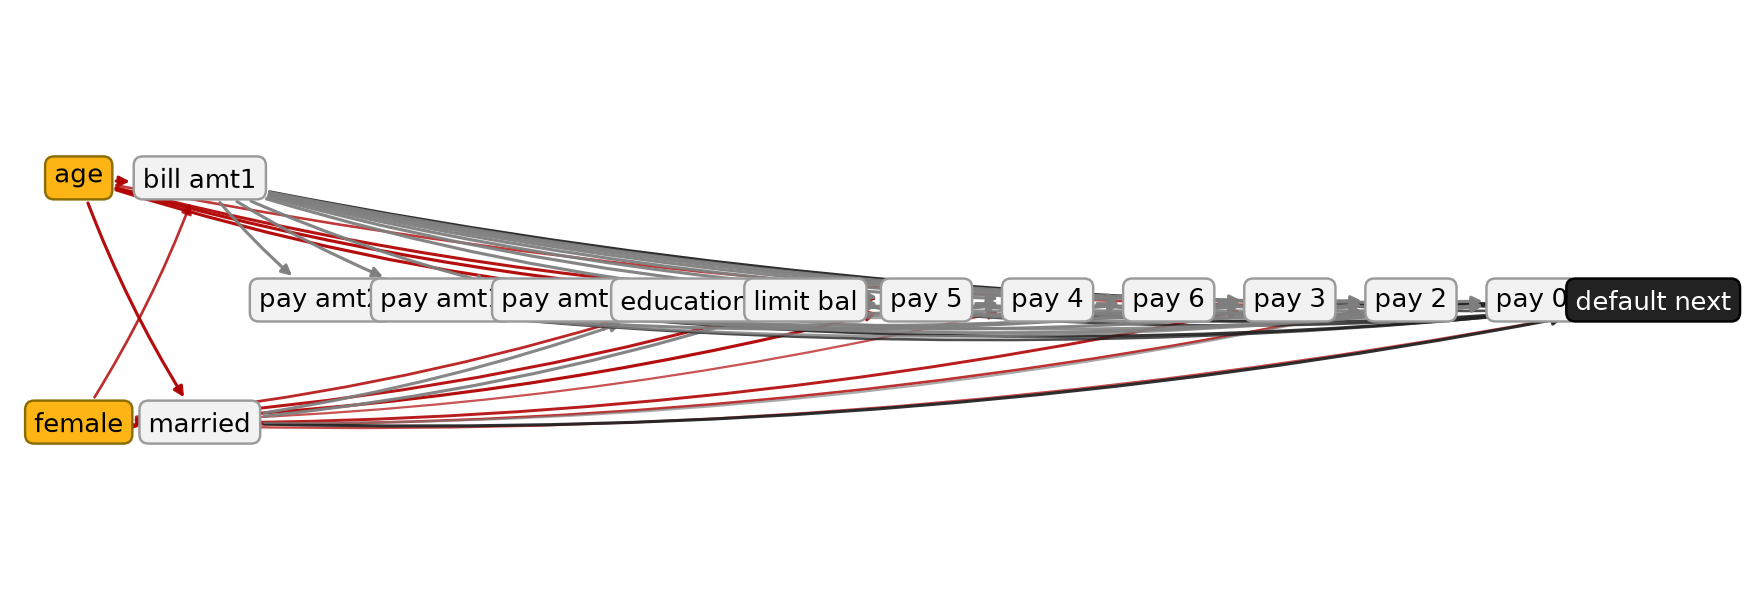

Edges INTO the label, and edges from age / education / credit limit (bootstrap probability >= 0.5):


,from,to,prob,coef_median,point_coef,pc_adjacent
9,age_years,married,1.00,0.455,0.455,True
56,limit_bal,pay_5,0.88,-0.333,-0.334,False
7,education,limit_bal,1.00,-0.267,-0.270,True
1,pay_0,default_next,1.00,0.249,0.247,True
4,age_years,education,1.00,0.152,0.151,True
6,age_years,limit_bal,1.00,0.141,0.145,True
49,limit_bal,pay_3,0.88,-0.098,-0.103,True
50,limit_bal,pay_2,0.88,-0.097,-0.098,True
5,bill_amt1,default_next,1.00,-0.076,-0.079,False
53,limit_bal,pay_4,0.88,-0.074,-0.076,False


In [19]:
if "taiwancredit" in RUN:
    out_t = li.STAGE0 / "taiwancredit"
    display(Image(filename=str(out_t / "fig_stage0_dag_TWN.png")))
    e = pd.read_csv(out_t / "edges_TWN.csv")
    print("Edges INTO the label, and edges from age / education / credit limit (bootstrap probability >= 0.5):")
    display(e[(e.prob >= 0.5) & ((e.to == "default_next") | e["from"].isin(["age_years", "education", "limit_bal", "female"]))]
            .sort_values("coef_median", key=abs, ascending=False).round(3))

## 4. Candidate risk strata
For each candidate subgroup: how big it is, its positive rate, and what Stage 0 said about the pathway. **A good targeted-noise stratum** has (a) a causal pathway into the label flagged by Stage 0, (b) enough positives to flip (at least ~200), and (c) a real-world reason labels could be wrong there.

- *Diabetes, age 80+:* Stage 0 marked the age pathway LIVE. Older patients are often discharged to nursing facilities, and a readmission at another hospital never reaches this record.
- *CDC, no care access:* no health coverage, or needed a doctor but could not afford one. Undiagnosed diabetes reads as "no" on a self-report survey; the CDC estimates about 27.6% of U.S. adults with diabetes are undiagnosed.
- *Taiwan credit, candidates:*
  - **age 25 or under:** young clients have thin credit histories; a missed payment is more often settled informally or by family and never recorded as a default.
  - **low credit limit (≤ NT$50,000):** the most financially fragile clients; their delinquent accounts are the ones most often restructured or sold to collectors, which can remove the default from the bank's own record.
  - **high-school education or less:** a socioeconomic group, with the same mechanism as above.
  Pick the one with a Stage 0 pathway into `default_next` **and** at least ~200 positives in training.

In [21]:
cands = {
    "diabetes130": {"age_80plus": "age_years >= 80", "age_70plus": "age_years >= 70",
                    "inpatient_2plus": "number_inpatient >= 2"},
    "cdcdiabetes": {"no_care_access": "AnyHealthcare == 0 or NoDocbcCost == 1",
                    "no_coverage": "AnyHealthcare == 0", "low_income": "Income <= 3"},
    "taiwancredit": {"age_25_or_under": "age_years <= 25", "low_limit": "limit_bal <= 50000",
                     "high_school_or_less": "education >= 3"},
}
TAGS = {"diabetes130": "Diab", "cdcdiabetes": "CDC", "taiwancredit": "TWN"}
rows = []
for name, qs in cands.items():
    if name not in RUN:
        continue
    cfg = li.CONFIGS[name]; tr = li.load_split(cfg, "train")
    fp = json.loads((li.STAGE0 / name / f"fingerprint_{TAGS[name]}.json").read_text())
    parents = ", ".join(f"{p['var']} ({p['prob']:.2f})" for p in fp.get("label_parents", []))
    for sname, q in qs.items():
        m = tr.eval(q).to_numpy(bool)
        rows.append({"dataset": name, "stratum": sname, "query": q, "share": m.mean(), "n": int(m.sum()),
                     "n_positive": int(tr.loc[m, cfg.label].sum()), "positive_rate": tr.loc[m, cfg.label].mean(),
                     "stage0_gate": fp.get("gate", {}).get("rung"), "stage0_label_parents": parents})
cand_table = li.save_merged(pd.DataFrame(rows), "01_candidate_strata.csv", show=0)
cand_table[cand_table.dataset.isin(list(RUN))].round(3)

kept 8 existing rows for ['cdcdiabetes', 'diabetes130', 'southgerman']
wrote D:\Documents\PhD_program\DISSERTATION_RELATED\Dissertation_Studies_code\safety_notebooks\label_integrity\results\01_candidate_strata.csv  (11 rows x 9 cols)


,dataset,stratum,query,share,n,n_positive,positive_rate,stage0_gate,stage0_label_parents
8,taiwancredit,age_25_or_under,age_years <= 25,0.129,2321,619,0.267,BOUNDED,"pay_0 (1.00), pay_2 (1.00), bill_amt1 (1.00), ..."
9,taiwancredit,low_limit,limit_bal <= 50000,0.254,4574,1428,0.312,BOUNDED,"pay_0 (1.00), pay_2 (1.00), bill_amt1 (1.00), ..."
10,taiwancredit,high_school_or_less,education >= 3,0.180,3230,780,0.241,BOUNDED,"pay_0 (1.00), pay_2 (1.00), bill_amt1 (1.00), ..."


## 5. Freeze the choice
Frozen Oct 9, 2026 and **never changed by rerunning this cell**: Diabetes → age 80+, CDC → no care access. (South German Credit → age ≤ 25 also stays in the file as a record, but the dataset is retired.)

**Taiwan credit: decide now, before notebook 02.** Read the Stage 0 output and the candidate table above, then set `TAIWAN_STRATUM` below to your choice. Running the cell writes the choice and today's date; once written it cannot be overwritten by this cell, which is what lets you tell a reviewer the group was fixed before any noise was injected. (If you truly must change it, delete the `taiwancredit` entry from `stage0_out/risk_strata_frozen.json` by hand and say so in the paper.)

In [ ]:
# >>> set this after reading Stage 0 (one of the candidates above, or your own query) <<<
# Left as None on purpose: the cell refuses to freeze until you choose. (On Oct 10 a queued run of
# this cell froze a placeholder before Stage 0 was reviewed; see the 'history' in the frozen file.)
# Taiwan was frozen on Oct 10, 2026 as low_limit ("limit_bal <= 50000"); rerunning this cell
# never changes an existing entry.
TAIWAN_STRATUM = None   # e.g. {"stratum_name": "low_limit", "stratum_query": "limit_bal <= 50000"}

new = {}
if "taiwancredit" in RUN:
    already = li.frozen_strata().get("taiwancredit") if (li.STAGE0 / "risk_strata_frozen.json").exists() else None
    if already:
        print(f"taiwancredit: already frozen on {already['frozen_on']} as {already['stratum_name']} -- left unchanged")
    elif TAIWAN_STRATUM is None:
        raise ValueError("Choose the Taiwan risk group first: set TAIWAN_STRATUM above, then rerun this cell.")
    else:
        new["taiwancredit"] = TAIWAN_STRATUM
FROZEN = li.freeze_strata(new)
print(json.dumps(FROZEN, indent=2))

taiwancredit: already frozen on 2026-10-10 12:47 -- left unchanged
{
  "diabetes130": {
    "stratum_name": "age_80plus",
    "stratum_query": "age_years >= 80",
    "frozen_on": "2026-10-09 14:46"
  },
  "cdcdiabetes": {
    "stratum_name": "no_care_access",
    "stratum_query": "AnyHealthcare == 0 or NoDocbcCost == 1",
    "frozen_on": "2026-10-09 14:46"
  },
  "southgerman": {
    "stratum_name": "age_25_or_under",
    "stratum_query": "age_years <= 25",
    "frozen_on": "2026-10-09 14:46"
  },
  "taiwancredit": {
    "stratum_name": "low_limit",
    "stratum_query": "limit_bal <= 50000",
    "frozen_on": "2026-10-10 12:47",
    "history": [
      {
        "stratum_name": "age_25_or_under",
        "stratum_query": "age_years <= 25",
        "frozen_on": "2026-10-10 12:26",
        "note": "Auto-frozen by a queued notebook cell using the placeholder value, before the Stage 0 output was reviewed."
      },
      {
        "changed_on": "2026-10-10 12:47",
        "note": "Changed to

## What to look for before moving on
- [ ] The assumption gate (top of each fingerprint) and the reason it gives. You will quote this in the paper.
- [ ] The label's parents. These should make clinical or financial sense.
- [ ] The age pathway's `P(any path)` — the evidence behind the stratum choice.
- [ ] `risk_strata_frozen.json` has a `taiwancredit` entry with today's date, and the Diabetes and CDC entries still say Oct 9.

**For the paper:** Stage 0 subsection = gate result + label parents + why the stratum was chosen + the DAG figure.